# 04 — DESI-Only $w(z)$ Reconstruction from the Seed Ensemble

This notebook propagates the random-seed dependence found in Notebook 03 into the DESI-only physical reconstruction. It compares the published equation, deterministic exponential fits, representative PySR exponential solutions, and the full ensemble of paper-like exponential solutions.

## Scope and interpretation

The algorithmic uncertainty is separated into two parts:

1. **Structural uncertainty:** how often PySR selects a paper-like exponential instead of another equation class.
2. **Within-class parameter spread:** the variation of $A$, $B$, $D_H/r_d$, and $w(z)$ among runs that selected an expression equivalent to $A\exp(Bz)$.

> The shaded bands in this notebook are conditional seed-dependent spreads. They are not observational confidence levels and must not be labelled as the paper's $1\sigma$, $2\sigma$, or $3\sigma$ regions.

## 1. Imports

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

SOFTWARE_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": metadata.version("scipy"),
}
display(pd.Series(SOFTWARE_VERSIONS, name="version").to_frame())

,version
python,3.13.11
numpy,2.5.2
pandas,2.3.3
scipy,1.18.1


## 2. Load the DESI data and 100-seed stability results

In [2]:
STABILITY_EXPERIMENT_ID = "targeted_maxsize7_100seeds_final_20260906"
EXPERIMENT_ID = "seed_ensemble_public_omegam0p30_rd101_20260908"


def find_project_root(start: Path) -> Path:
    """Return the nearest parent containing the required input files."""
    for candidate in (start, *start.parents):
        data_file = (
            candidate / "results" / "01_desi_data_check" / "desi_dr2_dh_over_rd.npz"
        )
        stability_file = (
            candidate / "results" / "03_desi_pysr_seed_stability"
            / STABILITY_EXPERIMENT_ID / "classified_summary.csv"
        )
        if data_file.is_file() and stability_file.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the Notebook 01 data and Notebook 03 stability results."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_FILE = (
    PROJECT_ROOT / "results" / "01_desi_data_check" / "desi_dr2_dh_over_rd.npz"
)
STABILITY_DIR = (
    PROJECT_ROOT / "results" / "03_desi_pysr_seed_stability"
    / STABILITY_EXPERIMENT_ID
)
STABILITY_FILE = STABILITY_DIR / "classified_summary.csv"
HIT_RATE_FILE = STABILITY_DIR / "exponential_hit_rates.csv"
NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / "results" / "04_desi_wz_reconstruction"
RESULTS_DIR = NOTEBOOK_RESULTS_DIR / EXPERIMENT_ID
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
for directory in (NOTEBOOK_RESULTS_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

with np.load(DATA_FILE) as data:
    z_data = data["z"].astype(float)
    y_data = data["y"].astype(float)
    public_covariance = data["covariance"].astype(float)
    public_sigma = data["sigma"].astype(float)
    tracers = data["tracers"].astype(str)

stability_results = pd.read_csv(STABILITY_FILE)
hit_rate_results = pd.read_csv(HIT_RATE_FILE)
PAPER_TABLE_SIGMA = np.array([0.425, 0.330, 0.193, 0.221, 0.516, 0.101])
paper_table_covariance = np.diag(PAPER_TABLE_SIGMA**2)
COVARIANCE_CONFIGS = {
    "public_full": public_covariance,
    "paper_table": paper_table_covariance,
}

assert len(z_data) == 6
assert len(stability_results) == 200, "Expected 100 seeds for two covariances."
assert set(stability_results["covariance"]) == set(COVARIANCE_CONFIGS)

print(f"DESI data: {DATA_FILE}")
print(f"Seed-stability input: {STABILITY_FILE}")
print(f"Output directory: {RESULTS_DIR}")
display(hit_rate_results)

DESI data: /Users/kemingliu/Desktop/Dark Energy/results/01_desi_data_check/desi_dr2_dh_over_rd.npz
Seed-stability input: /Users/kemingliu/Desktop/Dark Energy/results/03_desi_pysr_seed_stability/targeted_maxsize7_100seeds_final_20260906/classified_summary.csv
Output directory: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908


,covariance,exponential_hits,completed_seeds,hit_rate,wilson_95_lower,wilson_95_upper
0,paper_table,54,100,0.540000,0.442647,0.634394
1,public_full,66,100,0.660000,0.562775,0.745386


## 3. Define the paper-like exponential ensemble

Only rows classified in Notebook 03 as algebraically equivalent to $A\exp(Bz)$ enter the within-class reconstruction bands. The hit rate remains visible as a separate measure of structural uncertainty.

In [3]:
exponential_results = stability_results.loc[
    stability_results["model_class"] == "paper_like_exponential"
].copy()
exponential_results = exponential_results.dropna(
    subset=["exponential_A", "exponential_B"]
)

expected_hits = dict(
    zip(hit_rate_results["covariance"], hit_rate_results["exponential_hits"])
)
for covariance_name, group in exponential_results.groupby("covariance"):
    assert len(group) == int(expected_hits[covariance_name])

parameter_summary = (
    exponential_results
    .groupby("covariance")[["exponential_A", "exponential_B", "python_loss"]]
    .agg(["count", "mean", "std", "median", "min", "max"])
)
display(parameter_summary)

exponential_A                                                   \
                    count      mean      std    median       min       max   
covariance                                                                   
paper_table            54 27.895522 0.140532 27.816223 27.710659 28.129968   
public_full            66 27.900209 0.141096 27.809934 27.809934 28.120228   

            exponential_B                                                   \
                    count      mean      std    median       min       max   
covariance                                                                   
paper_table            54 -0.502302 0.003765 -0.500000 -0.508599 -0.500000   
public_full            66 -0.502377 0.003789 -0.500000 -0.508295 -0.499369   

            python_loss                                               
                  count     mean      std   median      min      max  
covariance                                                            
paper_table          54 0.533055 0.089314 0.561097 0.421558 1.000106  
public_full          66 0.502432 0.061416 0.539484 0.407375 0.604135

## 4. Recompute the deterministic exponential baselines

These fits optimize $A$ and $B$ directly under each covariance rather than searching over symbolic structures.

In [4]:
def exponential_distance(redshift, amplitude, slope):
    """Evaluate A * exp(B z)."""
    return amplitude * np.exp(slope * np.asarray(redshift, dtype=float))


def chi_square(observed, predicted, covariance):
    """Return r.T @ C^-1 @ r."""
    residual = np.asarray(predicted) - np.asarray(observed)
    return float(residual @ np.linalg.solve(covariance, residual))


PAPER_A, PAPER_B = 28.4, -0.519
baseline_rows = []
baseline_parameters = {}
for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    fitted_parameters, parameter_covariance = curve_fit(
        exponential_distance, z_data, y_data, p0=(PAPER_A, PAPER_B),
        sigma=covariance, absolute_sigma=True, maxfev=20_000,
    )
    amplitude, slope = fitted_parameters
    prediction = exponential_distance(z_data, amplitude, slope)
    fit_chi2 = chi_square(y_data, prediction, covariance)
    baseline_parameters[covariance_name] = fitted_parameters
    baseline_rows.append(
        {
            "covariance": covariance_name, "A": amplitude, "B": slope,
            "sigma_A": np.sqrt(parameter_covariance[0, 0]),
            "sigma_B": np.sqrt(parameter_covariance[1, 1]),
            "chi2": fit_chi2, "loss": fit_chi2 / len(z_data),
        }
    )
baseline_summary = pd.DataFrame(baseline_rows)
display(baseline_summary)

,covariance,A,B,sigma_A,sigma_B,chi2,loss
0,public_full,28.120222,-0.508294,0.390804,0.009317,2.444247,0.407375
1,paper_table,28.129755,-0.508460,0.384249,0.009249,2.529349,0.421558


## 5. Select representative exponential solutions

For each covariance, the actual run closest to the median $A,B$ pair and the lowest-loss exponential are retained. The latter is shown for comparison only and is not treated as uniquely preferred.

In [5]:
representative_rows = []
representative_solutions = {}
for covariance_name, group in exponential_results.groupby("covariance"):
    median_A = group["exponential_A"].median()
    median_B = group["exponential_B"].median()
    scale_A = group["exponential_A"].std()
    scale_B = group["exponential_B"].std()
    distance = (
        ((group["exponential_A"] - median_A) / scale_A) ** 2
        + ((group["exponential_B"] - median_B) / scale_B) ** 2
    )
    median_row = group.loc[distance.idxmin()]
    lowest_loss_row = group.loc[group["python_loss"].idxmin()]
    representative_solutions[covariance_name] = {
        "median_A": median_A, "median_B": median_B,
        "median_seed": int(median_row["seed"]),
        "lowest_loss_A": float(lowest_loss_row["exponential_A"]),
        "lowest_loss_B": float(lowest_loss_row["exponential_B"]),
        "lowest_loss_seed": int(lowest_loss_row["seed"]),
    }
    for label, row in (("median_representative", median_row),
                       ("lowest_loss_exponential", lowest_loss_row)):
        representative_rows.append(
            {
                "covariance": covariance_name, "selection": label,
                "seed": int(row["seed"]),
                "A": float(row["exponential_A"]),
                "B": float(row["exponential_B"]),
                "complexity": int(row["complexity"]),
                "loss": float(row["python_loss"]),
                "expression": row["sympy_expression"],
            }
        )
representative_summary = pd.DataFrame(representative_rows)
display(representative_summary)

,covariance,selection,seed,A,B,complexity,loss,expression
0,paper_table,median_representative,202544,27.816223,-0.500000,5,0.561097,27.81622317396154*sqrt(exp(-z))
1,paper_table,lowest_loss_exponential,202515,28.129755,-0.508460,6,0.421558,exp(3.3368279053808525 - 0.5084602992454287*z)
2,public_full,median_representative,202529,27.809934,-0.500000,5,0.539484,27.80993373954504*sqrt(exp(-z))
3,public_full,lowest_loss_exponential,202534,28.120222,-0.508294,6,0.407375,exp(z/(-1.9673637062397866) + 3.336488976574172)


## 6. Reconstruct $w(z)$ using Eq. (3)

For $\widetilde{D}_H=D_H/r_d$, the paper uses

$$
w(z)=-1-\frac{2(1+z)\widetilde{D}_H'(z)+3\gamma(1+z)^3\widetilde{D}_H^3(z)}{3[\widetilde{D}_H(z)-\gamma(1+z)^3\widetilde{D}_H^3(z)]},
$$

with $\gamma=\Omega_m H_0^2r_d^2/c^2$. The default comparison adopts $\Omega_m=0.30$ and $r_d=101\,h^{-1}\mathrm{Mpc}$, matching the paper's Figure 1 setup.

In [6]:
OMEGA_M = 0.30
RD_HINV_MPC = 101.0
RD_SIGMA_HINV_MPC = 2.3
C_KM_S = 299_792.458
GAMMA = OMEGA_M * (100.0 * RD_HINV_MPC / C_KM_S) ** 2
Z_GRID = np.linspace(0.0, 2.5, 501)


def reconstruct_exponential(amplitude, slope, redshift, gamma=GAMMA):
    """Return D_H/r_d and w(z) for A * exp(B z)."""
    redshift = np.asarray(redshift, dtype=float)
    distance = exponential_distance(redshift, amplitude, slope)
    derivative = slope * distance
    matter_term = gamma * (1.0 + redshift) ** 3 * distance**3
    denominator = 3.0 * (distance - matter_term)
    numerator = 2.0 * (1.0 + redshift) * derivative + 3.0 * matter_term
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        equation_of_state = -1.0 - numerator / denominator
    equation_of_state[np.abs(denominator) < 1e-10] = np.nan
    return distance, equation_of_state, denominator


paper_distance, paper_w, paper_denominator = reconstruct_exponential(
    PAPER_A, PAPER_B, Z_GRID
)
baseline_curves = {
    name: reconstruct_exponential(*parameters, Z_GRID)
    for name, parameters in baseline_parameters.items()
}
print(f"Gamma: {GAMMA:.8e}")
print(f"Minimum absolute paper denominator: {np.nanmin(np.abs(paper_denominator)):.6f}")

Gamma: 3.40504297e-04
Minimum absolute paper denominator: 2.109300


## 7. Propagate the within-exponential seed spread

The 2.5th, 16th, 50th, 84th, and 97.5th percentiles are calculated across exponential runs at each redshift.

In [7]:
QUANTILES = (2.5, 16.0, 50.0, 84.0, 97.5)
ensemble_curves = {}
band_rows = {"z": Z_GRID}
for covariance_name, group in exponential_results.groupby("covariance"):
    distance_curves, w_curves, minimum_denominators = [], [], []
    for amplitude, slope in zip(group["exponential_A"], group["exponential_B"]):
        distance, equation_of_state, denominator = reconstruct_exponential(
            amplitude, slope, Z_GRID
        )
        distance_curves.append(distance)
        w_curves.append(equation_of_state)
        minimum_denominators.append(np.nanmin(np.abs(denominator)))
    distance_curves = np.asarray(distance_curves)
    w_curves = np.asarray(w_curves)
    distance_quantiles = np.nanpercentile(distance_curves, QUANTILES, axis=0)
    w_quantiles = np.nanpercentile(w_curves, QUANTILES, axis=0)
    ensemble_curves[covariance_name] = {
        "distance_curves": distance_curves, "w_curves": w_curves,
        "distance_quantiles": distance_quantiles, "w_quantiles": w_quantiles,
        "minimum_denominators": np.asarray(minimum_denominators),
    }
    for index, quantile in enumerate(QUANTILES):
        suffix = str(quantile).replace(".", "p")
        band_rows[f"{covariance_name}_distance_q{suffix}"] = distance_quantiles[index]
        band_rows[f"{covariance_name}_w_q{suffix}"] = w_quantiles[index]

band_rows["paper_distance"] = paper_distance
band_rows["paper_w"] = paper_w
for name, (distance, equation_of_state, _) in baseline_curves.items():
    band_rows[f"{name}_baseline_distance"] = distance
    band_rows[f"{name}_baseline_w"] = equation_of_state
reconstruction_bands = pd.DataFrame(band_rows)
display(reconstruction_bands.head())

,z,paper_table_distance_q2p5,paper_table_w_q2p5,paper_table_distance_q16p0,paper_table_w_q16p0,paper_table_distance_q50p0,paper_table_w_q50p0,paper_table_distance_q84p0,paper_table_w_q84p0,paper_table_distance_q97p5,...,public_full_distance_q84p0,public_full_w_q84p0,public_full_distance_q97p5,public_full_w_q97p5,paper_distance,paper_w,public_full_baseline_distance,public_full_baseline_w,paper_table_baseline_distance,paper_table_baseline_w
0,0.000000,27.816223,-0.905136,27.816223,-0.905136,27.816223,-0.905136,28.129745,-0.904816,28.129770,...,28.120222,-0.904741,28.120222,-0.904741,28.400000,-0.901618,28.120222,-0.904741,28.129755,-0.904816
1,0.005000,27.746769,-0.906119,27.746769,-0.906119,27.746769,-0.906119,28.058321,-0.905812,28.058346,...,28.048846,-0.905736,28.048846,-0.905736,28.326398,-0.902589,28.048846,-0.905736,28.058331,-0.905812
2,0.010000,27.677489,-0.907116,27.677489,-0.907116,27.677489,-0.907116,27.987079,-0.906823,27.987104,...,27.977652,-0.906746,27.977652,-0.906746,28.252986,-0.903574,27.977652,-0.906746,27.987089,-0.906823
3,0.015000,27.608382,-0.908129,27.608382,-0.908129,27.608382,-0.908129,27.916018,-0.907850,27.916043,...,27.906637,-0.907771,27.906637,-0.907771,28.179764,-0.904574,27.906637,-0.907771,27.916028,-0.907850
4,0.020000,27.539447,-0.909156,27.539447,-0.909156,27.539447,-0.909156,27.845137,-0.908891,27.845162,...,27.835803,-0.908811,27.835804,-0.908811,28.106733,-0.905588,27.835804,-0.908811,27.845147,-0.908891


## 8. Primary reconstruction using the public covariance

The `public_full` covariance is used for the primary independent reconstruction.

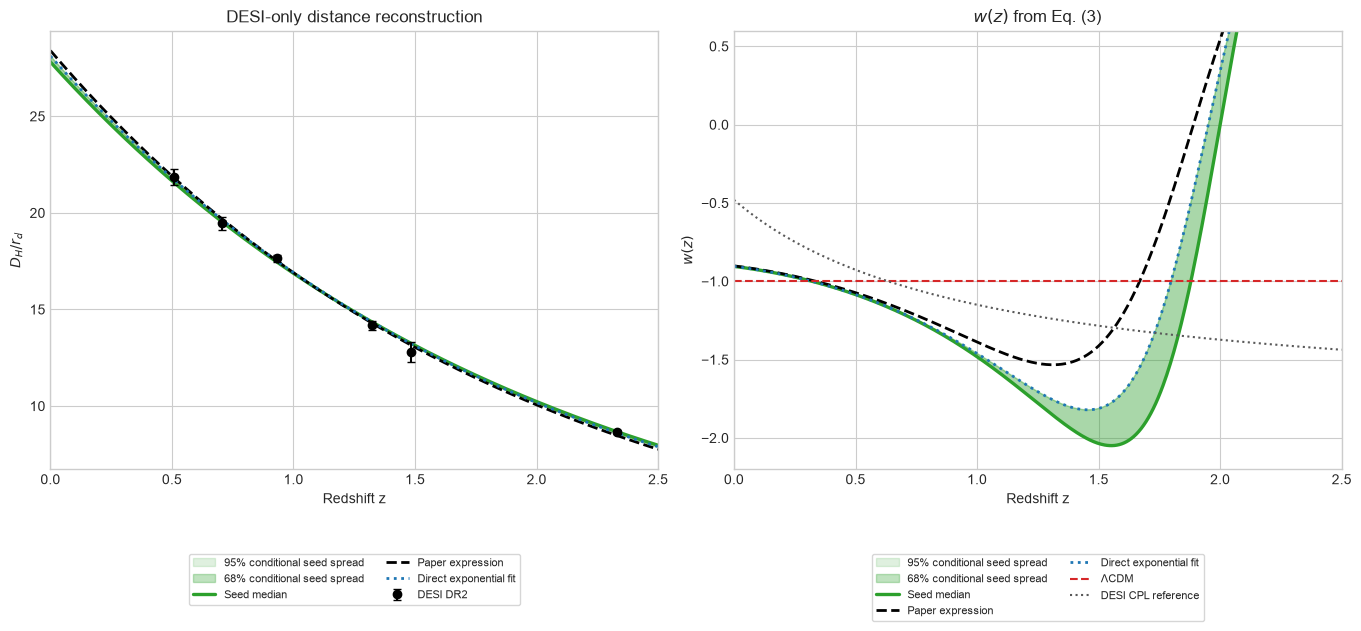

Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/figures/public_full_seed_ensemble_reconstruction.png


In [8]:
primary = ensemble_curves["public_full"]
distance_q025, distance_q16, distance_q50, distance_q84, distance_q975 = primary["distance_quantiles"]
w_q025, w_q16, w_q50, w_q84, w_q975 = primary["w_quantiles"]
baseline_distance, baseline_w, _ = baseline_curves["public_full"]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.2), constrained_layout=True)

axes[0].fill_between(Z_GRID, distance_q025, distance_q975, color="tab:green", alpha=0.15, label="95% conditional seed spread")
axes[0].fill_between(Z_GRID, distance_q16, distance_q84, color="tab:green", alpha=0.30, label="68% conditional seed spread")
axes[0].plot(Z_GRID, distance_q025, color="tab:green", linestyle="--", linewidth=1.0, alpha=0.9)
axes[0].plot(Z_GRID, distance_q975, color="tab:green", linestyle="--", linewidth=1.0, alpha=0.9)
axes[0].plot(Z_GRID, distance_q50, color="tab:green", linewidth=2.4, label="Seed median")
axes[0].plot(Z_GRID, paper_distance, "k--", linewidth=2.0, label="Paper expression")
axes[0].plot(Z_GRID, baseline_distance, color="tab:blue", linestyle=":", linewidth=2.0, label="Direct exponential fit")
axes[0].errorbar(z_data, y_data, yerr=public_sigma, fmt="o", color="black", capsize=3, zorder=5, label="DESI DR2")
axes[0].set(xlabel="Redshift z", ylabel=r"$D_H/r_d$", xlim=(0.0, 2.5), title="DESI-only distance reconstruction")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8, frameon=True)

axes[1].fill_between(Z_GRID, w_q025, w_q975, color="tab:green", alpha=0.15, label="95% conditional seed spread")
axes[1].fill_between(Z_GRID, w_q16, w_q84, color="tab:green", alpha=0.30, label="68% conditional seed spread")
axes[1].plot(Z_GRID, w_q025, color="tab:green", linestyle="--", linewidth=1.0, alpha=0.9)
axes[1].plot(Z_GRID, w_q975, color="tab:green", linestyle="--", linewidth=1.0, alpha=0.9)
axes[1].plot(Z_GRID, w_q50, color="tab:green", linewidth=2.4, label="Seed median")
axes[1].plot(Z_GRID, paper_w, "k--", linewidth=2.0, label="Paper expression")
axes[1].plot(Z_GRID, baseline_w, color="tab:blue", linestyle=":", linewidth=2.0, label="Direct exponential fit")
axes[1].axhline(-1.0, color="tab:red", linestyle="--", label=r"$\Lambda$CDM")
W0_CPL, WA_CPL = -0.48, -1.34
cpl_w = W0_CPL + WA_CPL * Z_GRID / (1.0 + Z_GRID)
axes[1].plot(Z_GRID, cpl_w, color="0.35", linestyle=":", label="DESI CPL reference")
axes[1].set(xlabel="Redshift z", ylabel=r"$w(z)$", xlim=(0.0, 2.5), ylim=(-2.2, 0.6), title=r"$w(z)$ from Eq. (3)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8, frameon=True)
PRIMARY_FIGURE = FIGURES_DIR / "public_full_seed_ensemble_reconstruction.png"
fig.savefig(PRIMARY_FIGURE, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved: {PRIMARY_FIGURE}")

## 9. Covariance sensitivity of the reconstructed $w(z)$

This compares the conditional seed medians and 68% ranges without assigning them an observational probability.

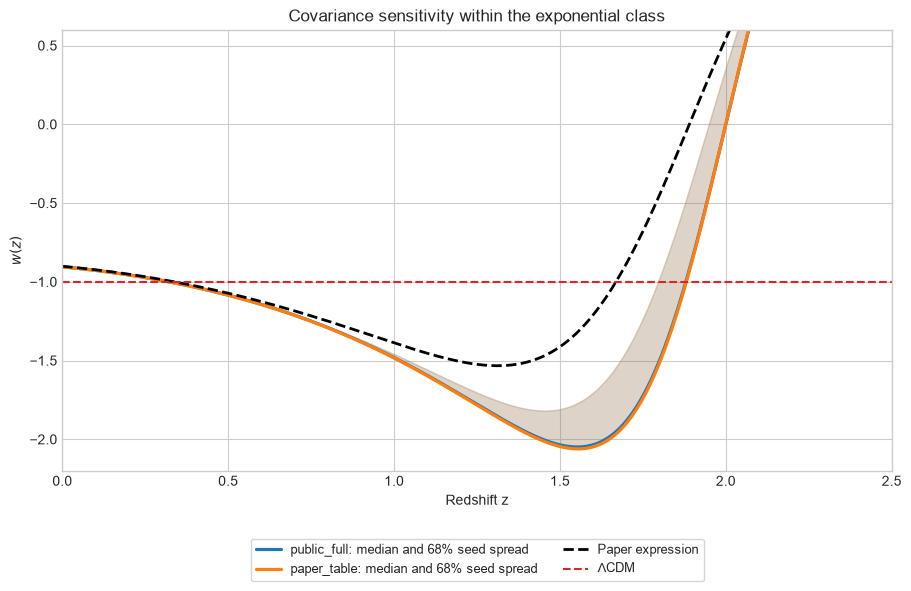

Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/figures/covariance_sensitivity_wz.png


In [9]:
fig, ax = plt.subplots(figsize=(9.0, 5.8), constrained_layout=True)
covariance_colors = {"public_full": "tab:blue", "paper_table": "tab:orange"}
for covariance_name, color in covariance_colors.items():
    w_quantiles = ensemble_curves[covariance_name]["w_quantiles"]
    ax.fill_between(Z_GRID, w_quantiles[1], w_quantiles[3], color=color, alpha=0.18)
    ax.plot(Z_GRID, w_quantiles[2], color=color, linewidth=2.3, label=f"{covariance_name}: median and 68% seed spread")
ax.plot(Z_GRID, paper_w, "k--", linewidth=2.0, label="Paper expression")
ax.axhline(-1.0, color="tab:red", linestyle="--", label=r"$\Lambda$CDM")
ax.set(xlabel="Redshift z", ylabel=r"$w(z)$", xlim=(0.0, 2.5), ylim=(-2.2, 0.6), title="Covariance sensitivity within the exponential class")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9, frameon=True)
COVARIANCE_FIGURE = FIGURES_DIR / "covariance_sensitivity_wz.png"
fig.savefig(COVARIANCE_FIGURE, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved: {COVARIANCE_FIGURE}")

## 10. Diagnostics

The denominator of Eq. (3) can become small at high redshift, amplifying small differences in the distance and derivative.

In [10]:
selected_redshifts = np.array([0.0, 0.5, 0.66, 1.0, 1.5, 2.0, 2.5])
selected_indices = [int(np.abs(Z_GRID - value).argmin()) for value in selected_redshifts]
diagnostic_rows = []
for redshift, index in zip(selected_redshifts, selected_indices):
    diagnostic_rows.append(
        {
            "z": redshift, "paper_w": paper_w[index],
            "public_full_seed_median_w": ensemble_curves["public_full"]["w_quantiles"][2, index],
            "paper_table_seed_median_w": ensemble_curves["paper_table"]["w_quantiles"][2, index],
            "public_full_direct_fit_w": baseline_curves["public_full"][1][index],
            "paper_table_direct_fit_w": baseline_curves["paper_table"][1][index],
        }
    )
selected_redshift_summary = pd.DataFrame(diagnostic_rows)
denominator_summary = pd.DataFrame(
    [
        {
            "covariance": name, "number_of_exponential_runs": len(curves["w_curves"]),
            "minimum_absolute_denominator": curves["minimum_denominators"].min(),
            "nonfinite_w_values": int((~np.isfinite(curves["w_curves"])).sum()),
        }
        for name, curves in ensemble_curves.items()
    ]
)
display(selected_redshift_summary)
display(denominator_summary)

,z,paper_w,public_full_seed_median_w,paper_table_seed_median_w,public_full_direct_fit_w,paper_table_direct_fit_w
0,0.000000,-0.901618,-0.904990,-0.905136,-0.904741,-0.904816
1,0.500000,-1.072733,-1.084775,-1.085349,-1.084530,-1.084834
2,0.660000,-1.160489,-1.183551,-1.184435,-1.181262,-1.181689
3,1.000000,-1.388194,-1.481673,-1.483986,-1.460788,-1.461573
4,1.500000,-1.412818,-2.035571,-2.045949,-1.812106,-1.812375
5,2.000000,0.543601,0.000000,0.000000,0.343859,0.350835
6,2.500000,1.743229,2.277160,2.290279,2.046676,2.047831


,covariance,number_of_exponential_runs,minimum_absolute_denominator,nonfinite_w_values
0,paper_table,54,1.128028,0
1,public_full,66,0.934067,0


## 11. Save reconstruction products and provenance

In [11]:
REPRESENTATIVE_FILE = TABLES_DIR / "representative_exponential_solutions.csv"
BASELINE_FILE = TABLES_DIR / "deterministic_exponential_baselines.csv"
BANDS_FILE = TABLES_DIR / "seed_dependent_reconstruction_bands.csv"
DIAGNOSTIC_FILE = TABLES_DIR / "wz_selected_redshifts.csv"
ARRAY_FILE = RESULTS_DIR / "seed_dependent_reconstruction.npz"
CONFIGURATION_FILE = RESULTS_DIR / "configuration.json"
representative_summary.to_csv(REPRESENTATIVE_FILE, index=False)
baseline_summary.to_csv(BASELINE_FILE, index=False)
reconstruction_bands.to_csv(BANDS_FILE, index=False)
selected_redshift_summary.to_csv(DIAGNOSTIC_FILE, index=False)
np.savez(
    ARRAY_FILE, z=Z_GRID, paper_distance=paper_distance, paper_w=paper_w,
    public_full_distance_quantiles=ensemble_curves["public_full"]["distance_quantiles"],
    public_full_w_quantiles=ensemble_curves["public_full"]["w_quantiles"],
    paper_table_distance_quantiles=ensemble_curves["paper_table"]["distance_quantiles"],
    paper_table_w_quantiles=ensemble_curves["paper_table"]["w_quantiles"],
    quantiles=np.asarray(QUANTILES),
)
configuration = {
    "experiment_id": EXPERIMENT_ID,
    "source_stability_experiment": STABILITY_EXPERIMENT_ID,
    "paper_expression": {"A": PAPER_A, "B": PAPER_B},
    "cosmology": {"omega_m": OMEGA_M, "rd_hinv_mpc": RD_HINV_MPC,
                    "rd_sigma_hinv_mpc": RD_SIGMA_HINV_MPC,
                    "c_km_s": C_KM_S, "gamma": GAMMA},
    "redshift_grid": {"minimum": 0.0, "maximum": 2.5, "points": len(Z_GRID)},
    "algorithmic_quantiles_percent": list(QUANTILES),
    "uncertainty_interpretation": (
        "Conditional seed-dependent spread among paper-like exponentials; "
        "not an observational confidence interval."
    ),
    "software_versions": SOFTWARE_VERSIONS,
}
with CONFIGURATION_FILE.open("w", encoding="utf-8") as stream:
    json.dump(configuration, stream, indent=2)
for path in (REPRESENTATIVE_FILE, BASELINE_FILE, BANDS_FILE, DIAGNOSTIC_FILE,
             ARRAY_FILE, CONFIGURATION_FILE, PRIMARY_FIGURE, COVARIANCE_FIGURE):
    print(f"Saved: {path}")

Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/tables/representative_exponential_solutions.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/tables/deterministic_exponential_baselines.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/tables/seed_dependent_reconstruction_bands.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/tables/wz_selected_redshifts.csv
Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/seed_dependent_reconstruction.npz
Saved: /Users/kemingliu/Desktop/Dark Energy/results/04_desi_wz_reconstruction/seed_ensemble_public_omegam0p30_rd101_20260908/configuration.json
Saved: /Users/kemingli

## 12. Interpretation

The paper-like exponential is the most frequently selected low-complexity structure, but it is not selected for every seed. The bands here quantify coefficient variation only after conditioning on that class. Structural uncertainty remains represented by the 66% (`public_full`) and 54% (`paper_table`) hit rates from Notebook 03.

The median exponential solutions and deterministic fits provide complementary summaries. A single lowest-loss PySR expression is not treated as uniquely preferred. Small differences can be amplified by the derivative and denominator in Eq. (3), particularly at high redshift.

The next distinct task is observational uncertainty propagation using covariance-based data realizations. Those Monte Carlo confidence levels must remain separate from the algorithmic seed bands produced here.